In [7]:
from __future__ import annotations

from sklearn.datasets import make_moons
import torch
from torch import nn

from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty
from probly.representer import representer
from probly.transformation import dropout

In [8]:
X, y = make_moons(n_samples=500, noise=0.05, random_state=0)
X_tensor = torch.from_numpy(X).float()
y_tensor = torch.from_numpy(y).long()

In [9]:
base_model = MLPClassifier()

dropout_model = dropout(
    base_model,
    p=0.5,  # zeroing probability (kept active at inference)
    predictor_type="logit_classifier",
    shared_mask=True,  # one mask per forward pass, shared across the batch
)

In [10]:
opt = torch.optim.Adam(dropout_model.parameters(), lr=1e-3)

dropout_model.train()
for epoch in range(300):
    opt.zero_grad()
    out = dropout_model(X_tensor)
    loss = nn.functional.cross_entropy(out, y_tensor)
    loss.backward()
    opt.step()

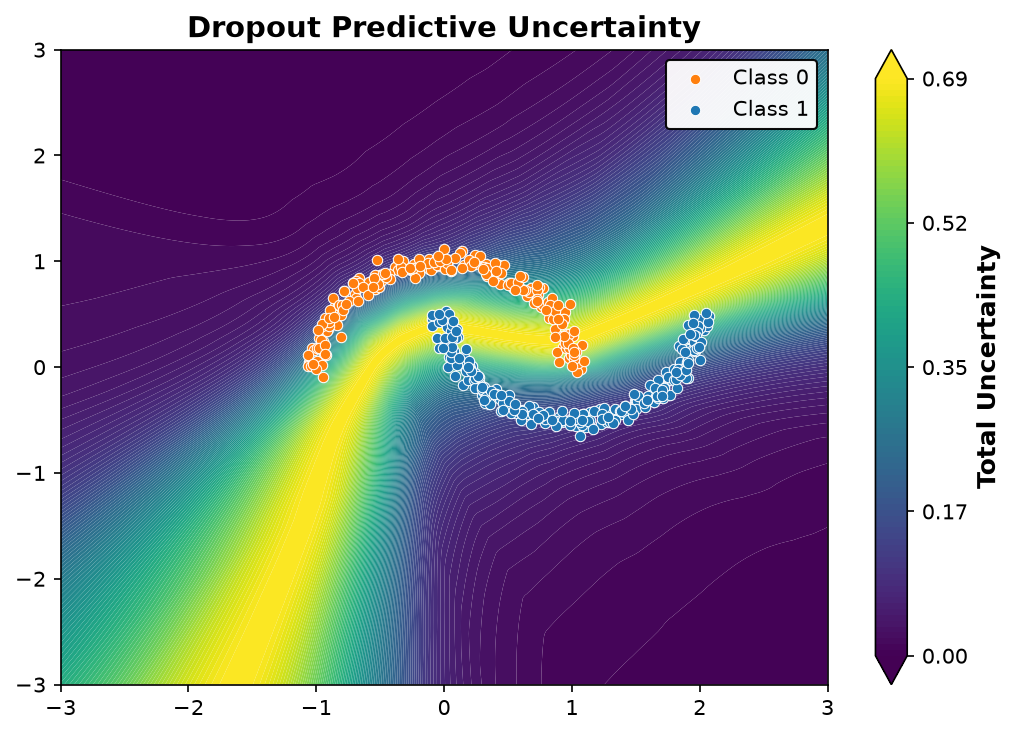

In [11]:
dropout_model.eval()
rep = representer(dropout_model, num_samples=400)

plot = plot_example_uncertainty(X, y, rep, title="Dropout Predictive Uncertainty", notion="total")
plot.show()